#Churn analysis
Why recall matters?

The cost of getting a new customer heavily outweighs the cost of retaining an old one.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier


In [47]:
df = pd.read_csv("https://raw.githubusercontent.com/SaismithSahoo/churn-project/main/Data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.isnull().sum()


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [6]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


(7043, 21)

In [7]:
df["Churn"].value_counts(normalize=True)*100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [8]:

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

there were new customers(tenure=0) with blank totalCharge, so I filled them with 0


In [9]:
df = df.drop("customerID", axis=1)
df["Churn"]=df["Churn"].map({"Yes":1,"No":0})

In [10]:
col_cat= df.select_dtypes(include="object").columns
for col in col_cat:
  print(col, df[col].unique())

gender ['Female' 'Male']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


In [39]:
df = df.replace({"No internet service":"No","No phone service":"No"})


Here, "No internet service" and "No phone service" were replaced by "No" because they meant that the customer didnt opt
for internet service thus wuld not have the add ons, which essentially means no.
Thus, i decided to remove the redundant option

In [12]:
print(df.dtypes)
print(df.isnull().sum().sum())
print(df.shape)

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object
0
(7043, 20)


# EDA

In [13]:

for col in col_cat:
  print(df.groupby(col)["Churn"].mean().sort_values(ascending=True))
  print()

gender
Male      0.261603
Female    0.269209
Name: Churn, dtype: float64

Partner
Yes    0.196649
No     0.329580
Name: Churn, dtype: float64

Dependents
Yes    0.154502
No     0.312791
Name: Churn, dtype: float64

PhoneService
No     0.249267
Yes    0.267096
Name: Churn, dtype: float64

MultipleLines
No     0.250246
Yes    0.286099
Name: Churn, dtype: float64

InternetService
No             0.074050
DSL            0.189591
Fiber optic    0.418928
Name: Churn, dtype: float64

OnlineSecurity
Yes    0.146112
No     0.313296
Name: Churn, dtype: float64

OnlineBackup
Yes    0.215315
No     0.291721
Name: Churn, dtype: float64

DeviceProtection
Yes    0.225021
No     0.286518
Name: Churn, dtype: float64

TechSupport
Yes    0.151663
No     0.311862
Name: Churn, dtype: float64

StreamingTV
No     0.243312
Yes    0.300702
Name: Churn, dtype: float64

StreamingMovies
No     0.243795
Yes    0.299414
Name: Churn, dtype: float64

Contract
Two year          0.028319
One year          0.112695
Month

In [14]:
print(df.groupby("Churn")[["tenure","MonthlyCharges","TotalCharges"]].mean())

          tenure  MonthlyCharges  TotalCharges
Churn                                         
0      37.569965       61.265124   2549.911442
1      17.979133       74.441332   1531.796094


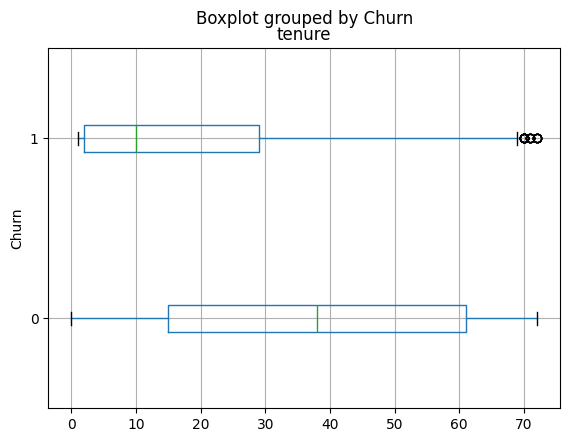

In [15]:
df.boxplot(column="tenure",by="Churn",vert=False)
plt.show()

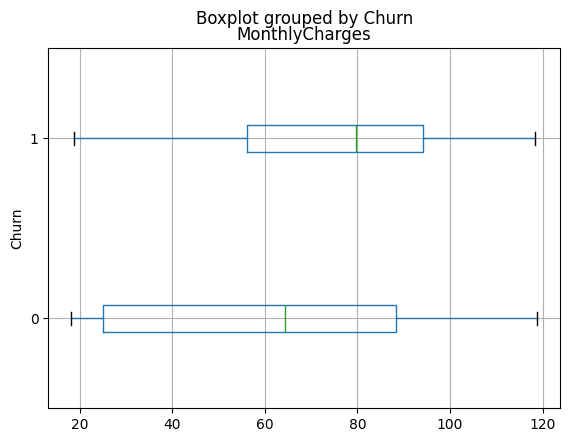

In [16]:
df.boxplot(column="MonthlyCharges", by="Churn",vert=False)
plt.show()

In [17]:
print(df.groupby(["Contract","InternetService"])["Churn"].agg(["mean","count"]))

                                    mean  count
Contract       InternetService                 
Month-to-month DSL              0.322159   1223
               Fiber optic      0.546053   2128
               No               0.188931    524
One year       DSL              0.092982    570
               Fiber optic      0.192950    539
               No               0.024725    364
Two year       DSL              0.019108    628
               Fiber optic      0.072261    429
               No               0.007837    638


Month-to-month fiber customers churn at 54.6%, the highest-risk segment

# Model Testing


In [18]:
X=df.drop("Churn",axis=1)
y=df["Churn"]

In [19]:
X=pd.get_dummies(X,drop_first=True)
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,False,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,True,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,False,False,...,True,True,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,True,...,False,False,False,False,False,False,True,False,True,False


In [20]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [21]:
print(X.shape)
print(X_train.shape)
print(X_test.shape)
print(y_train.mean())
print(y_test.mean())

(7043, 23)
(5634, 23)
(1409, 23)
0.2653532126375577
0.2654364797728886


In [22]:
dummy=DummyClassifier(strategy="most_frequent")
dummy.fit(X_train,y_train)
dummy_pred=dummy.predict(X_test)
print(classification_report(y_test,dummy_pred,zero_division=0))

              precision    recall  f1-score   support

           0       0.73      1.00      0.85      1035
           1       0.00      0.00      0.00       374

    accuracy                           0.73      1409
   macro avg       0.37      0.50      0.42      1409
weighted avg       0.54      0.73      0.62      1409



In [23]:
model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
y_pred= model.predict(X_test)
y_prob= model.predict_proba(X_test)[:,1]

In [24]:
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

[[926 109]
 [163 211]]
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.8419230669870056


In [25]:
lr=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
rf = RandomForestClassifier(n_estimators=200, random_state=42)

In [26]:
for name, m in [("Logistic Regression", lr), ("Random Forest", rf)]:
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring="roc_auc")
    print(name, scores.round(3), "mean:", scores.mean().round(3))

Logistic Regression [0.864 0.853 0.851 0.836 0.824] mean: 0.846
Random Forest [0.841 0.831 0.822 0.818 0.805] mean: 0.823


In [27]:
rf2 = RandomForestClassifier(n_estimators=300, max_depth=6,
                             min_samples_leaf=10, random_state=42)
scores = cross_val_score(rf2, X_train, y_train, cv=5, scoring="roc_auc")
print("Tuned RF", scores.round(3), "mean:", scores.mean().round(3))

Tuned RF [0.86  0.856 0.848 0.84  0.824] mean: 0.846


In [28]:

gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                    max_iter=200, random_state=42)
scores = cross_val_score(gb, X_train, y_train, cv=5, scoring="roc_auc")
print("Gradient Boosting", scores.round(3), "mean:", scores.mean().round(3))

Gradient Boosting [0.866 0.854 0.849 0.84  0.826] mean: 0.847


Three different model types all scored about 0.846, so I chose logistic regression because it is simpler and explainable

In [40]:
full_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
full_model.fit(X_train, y_train)
full_prob = full_model.predict_proba(X_test)[:, 1]
print("Test ROC-AUC (with TotalCharges):", roc_auc_score(y_test, full_prob))

Test ROC-AUC (with TotalCharges): 0.8419230669870056


In [41]:
coefs = pd.Series(full_model[-1].coef_[0], index=X_train.columns)
print(coefs.sort_values())

tenure                                  -1.254069
MonthlyCharges                          -0.842827
InternetService_No                      -0.619421
Contract_Two year                       -0.586311
Contract_One year                       -0.284816
OnlineSecurity_Yes                      -0.129169
TechSupport_Yes                         -0.106050
Dependents_Yes                          -0.102298
OnlineBackup_Yes                        -0.018172
PaymentMethod_Credit card (automatic)   -0.013487
PhoneService_Yes                        -0.003790
Partner_Yes                              0.010156
gender_Male                              0.011197
PaymentMethod_Mailed check               0.030791
DeviceProtection_Yes                     0.046967
SeniorCitizen                            0.053356
PaymentMethod_Electronic check           0.179992
PaperlessBilling_Yes                     0.182899
MultipleLines_Yes                        0.210185
StreamingTV_Yes                          0.244376


In [31]:
X_train2 = X_train.drop("TotalCharges", axis=1)
scores = cross_val_score(lr, X_train2, y_train, cv=5, scoring="roc_auc")
print(scores.round(3), "mean:", scores.mean().round(3))

[0.863 0.852 0.849 0.834 0.824] mean: 0.844


In [32]:

X_test2 = X_test.drop("TotalCharges", axis=1)


Dropping TotalCharges changed the CV score from 0.846 to 0.844, so I removed it

In [33]:
train_prob = cross_val_predict(lr, X_train2, y_train, cv=5,method="predict_proba")[:, 1]

# Final Model




In [34]:
#Threshold Function

def threshold_table(y_true, prob, thresholds=(0.5, 0.4, 0.3, 0.2)):
    """Print recall, precision and number flagged at each threshold."""
    n_churn = y_true.sum()
    for t in thresholds:
        pred = (prob >= t).astype(int)
        tp = ((pred == 1) & (y_true == 1)).sum()
        print(f"threshold {t}: recall={tp/n_churn:.2f}, "
              f"precision={tp/pred.sum():.2f}, flagged={pred.sum()}")


In [35]:
threshold_table(y_train, train_prob)

threshold 0.5: recall=0.54, precision=0.66, flagged=1235
threshold 0.4: recall=0.65, precision=0.60, flagged=1623
threshold 0.3: recall=0.76, precision=0.54, flagged=2084
threshold 0.2: recall=0.86, precision=0.48, flagged=2692


In [42]:
final_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
final_model.fit(X_train2, y_train)
test_prob = final_model.predict_proba(X_test2)[:, 1]

print("Final model test ROC-AUC:", roc_auc_score(y_test, test_prob))
threshold_table(y_test, test_prob)


Final model test ROC-AUC: 0.8388824304425329
threshold 0.5: recall=0.55, precision=0.64, flagged=324
threshold 0.4: recall=0.67, precision=0.57, flagged=438
threshold 0.3: recall=0.74, precision=0.52, flagged=531
threshold 0.2: recall=0.85, precision=0.47, flagged=677


In [43]:
print(pd.Series(final_model[-1].coef_[0], index=X_train2.columns).sort_values())

tenure                                  -0.800694
MonthlyCharges                          -0.776006
InternetService_No                      -0.606860
Contract_Two year                       -0.581342
Contract_One year                       -0.283930
OnlineSecurity_Yes                      -0.119483
Dependents_Yes                          -0.108135
TechSupport_Yes                         -0.095455
PaymentMethod_Credit card (automatic)   -0.013854
OnlineBackup_Yes                        -0.001248
Partner_Yes                              0.010484
gender_Male                              0.012287
PhoneService_Yes                         0.015042
PaymentMethod_Mailed check               0.046735
SeniorCitizen                            0.053412
DeviceProtection_Yes                     0.060737
PaperlessBilling_Yes                     0.181013
PaymentMethod_Electronic check           0.182629
MultipleLines_Yes                        0.224064
StreamingTV_Yes                          0.262414


Tenure and two-year contracts lower churn risk most. Fiber optic and electronic check raise it

#Conclusion
The threshold option 0.2 catches more churners but it flags more loyal customers(False alarms). The cost per false alarm stays the same, but the number of false alarms rises but the cost of losing a customer heavily outweighs that.


As we increase the threshold, we raise less false alarms but catch less churners.

#My Recommendation
0.3 contacts about 38% of customers, and 0.2 contacts about 48%.

Lowering the threshold to 0.2 is better as it catches about 85% of churners and about 52% of flagged customers actually churn.

Else, the threshold 0.3 maintains a churner catch rate of 74% and about 52% of flagged customers actually churn.